In [1]:
# Imports

import os

import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from sqlalchemy import URL, create_engine

In [2]:
# Load

load_dotenv()

url = URL.create(
    "postgresql+psycopg",
    username=os.environ["PGUSER"],
    password=os.getenv("PGPASSWORD") or None,
    host=os.environ["PGHOST"],
    port=int(os.environ["PGPORT"]),
    database=os.environ["PGDATABASE"],
)

engine = create_engine(url)

query = """
SELECT time, temperature_2m
FROM practice_017.weather_hourly
WHERE time >= TIMESTAMPTZ '2025-01-01 00:00:00 America/Edmonton'
  AND time <  TIMESTAMPTZ '2025-04-01 00:00:00 America/Edmonton'
ORDER BY time
"""

df = pd.read_sql_query(query, engine)

df["time"] = pd.to_datetime(df["time"], utc = True).dt.tz_convert("America/Edmonton")

df.head()

,time,temperature_2m
0,2025-01-01 00:00:00-07:00,-9.8
1,2025-01-01 01:00:00-07:00,-9.8
2,2025-01-01 02:00:00-07:00,-10.1
3,2025-01-01 03:00:00-07:00,-11.5
4,2025-01-01 04:00:00-07:00,-11.2


In [3]:
# Inspect

# Structure
print(df["time"].min(), "to", df["time"].max(), "\n")
print("Shape:", df.shape, "\n")
print("Dtypes:")
print(df.dtypes, "\n")

# Missingness
print("Any Nulls:", df.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", df.duplicated().any())
print("Duplicate Times:", df["time"].duplicated().any(), "\n")

# Temporal Sanity
print("Non-Monotonic Times:", not df["time"].is_monotonic_increasing)
print("Unexpected Time Deltas:", df["time"].diff().dropna().ne(pd.Timedelta(hours = 1)).any(), "\n")

# Value Sanity
display(df[["temperature_2m"]].describe().T)

2025-01-01 00:00:00-07:00 to 2025-03-31 23:00:00-06:00 

Shape: (2073, 2) 

Dtypes:
time              datetime64[us, America/Edmonton]
temperature_2m                             float64
dtype: object 

Any Nulls: False 

Duplicate Rows: False
Duplicate Times: False 

Non-Monotonic Times: False
Unexpected Time Deltas: True 



,count,mean,std,min,25%,50%,75%,max
temperature_2m,2073.0,-4.694935,9.46695,-26.9,-12.5,-2.4,2.2,14.0


In [4]:
# Additional Inspect

unexpected_timedeltas = (df[["time"]].assign(next_time = lambda x: x["time"].shift(-1))
                                     .assign(delta = lambda x: x["next_time"] - x["time"])
                                     .dropna()
                                     .loc[lambda x: x["delta"].gt(pd.Timedelta(hours = 1))]
                                     .sort_values("delta", ascending = False)
                                     .reset_index(drop = True))

missing = (unexpected_timedeltas["delta"] - pd.Timedelta(hours = 1)).sum()

expected_time = ((pd.Timestamp("2025-04-01", tz = "America/Edmonton")
                  - pd.Timestamp("2025-01-01", tz = "America/Edmonton"))
                  / pd.Timedelta(hours = 1))

display(unexpected_timedeltas)

print("Total Time Missing:", missing, "\n")

print(f"Time Missing Pct: {(missing / pd.Timedelta(hours = 1)) / expected_time:.2%}")

,time,next_time,delta
0,2025-02-01 17:00:00-07:00,2025-02-03 09:00:00-07:00,1 days 16:00:00
1,2025-01-26 14:00:00-07:00,2025-01-28 05:00:00-07:00,1 days 15:00:00
2,2025-01-10 20:00:00-07:00,2025-01-10 22:00:00-07:00,0 days 02:00:00
3,2025-01-13 16:00:00-07:00,2025-01-13 18:00:00-07:00,0 days 02:00:00
4,2025-01-17 07:00:00-07:00,2025-01-17 09:00:00-07:00,0 days 02:00:00
5,2025-01-20 03:00:00-07:00,2025-01-20 05:00:00-07:00,0 days 02:00:00
6,2025-01-25 10:00:00-07:00,2025-01-25 12:00:00-07:00,0 days 02:00:00
7,2025-02-04 12:00:00-07:00,2025-02-04 14:00:00-07:00,0 days 02:00:00
8,2025-02-04 16:00:00-07:00,2025-02-04 18:00:00-07:00,0 days 02:00:00
9,2025-02-06 11:00:00-07:00,2025-02-06 13:00:00-07:00,0 days 02:00:00


Total Time Missing: 3 days 14:00:00 

Time Missing Pct: 3.98%


In [5]:
# Clean
# 2 Major Outages  
# 9 Isolated Missing Hours

# For Isolated Hours we can interpolate from adjacent observations for reasonable estimation and impact to if the day is freezing or not

# For Major Outages we cant reliably use simple interpolation.
# Partial days have some useful evidence, while entirely missing days do not.

# Because major outages could complicate the outcome we will defer the estimation to see if cleaning is necessary.
# Major outages could very reasonably change the longest-streak conclusion.

In [6]:
# Analyze

expected = pd.date_range(start = "2025-01-01", end = "2025-04-01", freq = "h",tz = "America/Edmonton", inclusive = "left")

daily = (df.set_index("time")
           .reindex(expected)
           .resample("D")
           .agg(avg_temp = ("temperature_2m", "mean"),
                missing_hours = ("temperature_2m", lambda x: x.isna().sum()))
           .rename_axis("date")
           .reset_index()
           .assign(freezing = lambda x: x["avg_temp"].lt(0),
                   possible_freezing = lambda x: x["freezing"] | x["missing_hours"].gt(0))
)


def streaks(daily, column):
    groups = (~daily[column]).cumsum()

    result = (daily.loc[daily[column]]
                   .groupby(groups)
                   .agg(start = ("date", "min"),
                        end = ("date", "max"),
                        days = ("date", "size"),
                        missing_days = ("missing_hours", lambda x: x.gt(0).sum()),
                        missing_hours = ("missing_hours", "sum"))
                   .sort_values(["days", "start"], ascending = [False, True])
                   .reset_index(drop = True)
        )

    return result


available_streaks = streaks(daily, "freezing")
possible_streaks = streaks(daily, "possible_freezing")

print("Longest Available Streak:", available_streaks["days"].max())
print("Longest Possible Streak:", possible_streaks["days"].max())

display(available_streaks.head(10))
display(possible_streaks.head(10))

Longest Available Streak: 18
Longest Possible Streak: 22


,start,end,days,missing_days,missing_hours
0,2025-02-03 00:00:00-07:00,2025-02-20 00:00:00-07:00,18,3,12
1,2025-01-17 00:00:00-07:00,2025-01-26 00:00:00-07:00,10,4,12
2,2025-03-12 00:00:00-06:00,2025-03-19 00:00:00-06:00,8,0,0
3,2025-01-01 00:00:00-07:00,2025-01-07 00:00:00-07:00,7,0,0
4,2025-01-30 00:00:00-07:00,2025-02-01 00:00:00-07:00,3,1,6
5,2025-03-28 00:00:00-06:00,2025-03-30 00:00:00-06:00,3,1,1
6,2025-01-12 00:00:00-07:00,2025-01-13 00:00:00-07:00,2,1,1
7,2025-01-09 00:00:00-07:00,2025-01-09 00:00:00-07:00,1,0,0
8,2025-03-04 00:00:00-07:00,2025-03-04 00:00:00-07:00,1,0,0
9,2025-03-06 00:00:00-07:00,2025-03-06 00:00:00-07:00,1,0,0


,start,end,days,missing_days,missing_hours
0,2025-01-30 00:00:00-07:00,2025-02-20 00:00:00-07:00,22,5,42
1,2025-01-17 00:00:00-07:00,2025-01-28 00:00:00-07:00,12,6,41
2,2025-03-12 00:00:00-06:00,2025-03-19 00:00:00-06:00,8,0,0
3,2025-01-01 00:00:00-07:00,2025-01-07 00:00:00-07:00,7,0,0
4,2025-03-28 00:00:00-06:00,2025-03-30 00:00:00-06:00,3,1,1
5,2025-01-09 00:00:00-07:00,2025-01-10 00:00:00-07:00,2,1,1
6,2025-01-12 00:00:00-07:00,2025-01-13 00:00:00-07:00,2,1,1
7,2025-03-04 00:00:00-07:00,2025-03-04 00:00:00-07:00,1,0,0
8,2025-03-06 00:00:00-07:00,2025-03-06 00:00:00-07:00,1,0,0
9,2025-03-10 00:00:00-06:00,2025-03-10 00:00:00-06:00,1,0,0


In [7]:
# Investigate Missingness
# January 30 – February 20 is the longest possible streak (22 days).
# Examine the missing intervals and surrounding temperatures before estimation.

start = possible_streaks.loc[0, "start"]
end = possible_streaks.loc[0, "end"]

temperature = df.set_index("time")["temperature_2m"]

gaps = (unexpected_timedeltas.loc[lambda x: (x["next_time"] > start) & (x["time"] < end + pd.DateOffset(days = 1))]
                             .assign(missing_hours = lambda x: (x["delta"] / pd.Timedelta(hours = 1) - 1).astype(int),
                                     before_temp = lambda x: x["time"].map(temperature),
                                     after_temp = lambda x: x["next_time"].map(temperature))
                             .sort_values("time")
                             .rename(columns = {"time": "before_time", "next_time": "after_time"})
                             .reset_index(drop = True)
)

display(gaps[["before_time", "after_time", "missing_hours", "before_temp", "after_temp"]])

,before_time,after_time,missing_hours,before_temp,after_temp
0,2025-02-01 17:00:00-07:00,2025-02-03 09:00:00-07:00,39,-16.3,-24.8
1,2025-02-04 12:00:00-07:00,2025-02-04 14:00:00-07:00,1,-23.9,-23.3
2,2025-02-04 16:00:00-07:00,2025-02-04 18:00:00-07:00,1,-23.2,-24.6
3,2025-02-06 11:00:00-07:00,2025-02-06 13:00:00-07:00,1,-15.5,-9.7


In [8]:
# Assess Missing-Day Classification
# -1 * (number of observed hours * average temperature of those hours) / number of missing hours = the average temperature needed to reach 0˚
# for example if 18 hours average at -3˚c: -(18hr * 3˚c) / 6hr = +9˚c --> (-54 + 54)/24 = 0 

display(daily.loc[daily["date"].between(start, end) & daily["missing_hours"].gt(0), ["date", "avg_temp", "missing_hours"]]
             .assign(observed_hours = lambda x: 24 - x["missing_hours"],
                     required_missing_avg = lambda x: -x["avg_temp"] * x["observed_hours"] / x["missing_hours"])
)

,date,avg_temp,missing_hours,observed_hours,required_missing_avg
31,2025-02-01 00:00:00-07:00,-11.472222,6,18,34.416667
32,2025-02-02 00:00:00-07:00,NaN,24,0,NaN
33,2025-02-03 00:00:00-07:00,-23.520000,9,15,39.200000
34,2025-02-04 00:00:00-07:00,-24.395455,2,22,268.350000
36,2025-02-06 00:00:00-07:00,-18.908696,1,23,434.900000


In [9]:
# February 1, 3, 4, and 6 would require implausibly high missing temperatures to become nonfreezing.
# We will qualify them as freezing days

# February 2 has no observations and remains unresolved.
# Estimate its freezing probability using historical winter days.

# Given that the day before and the day after were freezing (we are fairly sure), what's the probability the middle day was also freezing?

In [10]:
# Load Historical Data

historical_query = """
SELECT time, temperature_2m
FROM practice_017.weather_hourly
WHERE time >= TIMESTAMPTZ '2020-01-01 00:00:00 America/Edmonton'
  AND time <  TIMESTAMPTZ '2025-01-01 00:00:00 America/Edmonton'
  AND EXTRACT(MONTH FROM time AT TIME ZONE 'America/Edmonton') IN (1, 2)
ORDER BY time
"""

historical = pd.read_sql_query(historical_query, engine)

historical["time"] = pd.to_datetime(historical["time"], utc = True).dt.tz_convert("America/Edmonton")

historical.head()

,time,temperature_2m
0,2020-01-01 00:00:00-07:00,0.8
1,2020-01-01 01:00:00-07:00,-0.2
2,2020-01-01 02:00:00-07:00,-0.2
3,2020-01-01 03:00:00-07:00,-0.6
4,2020-01-01 04:00:00-07:00,-0.7


In [11]:
# Historical Inspect

# Structure
print(historical["time"].min(), "to", historical["time"].max(), "\n")
print("Shape:", historical.shape, "\n")
print("Dtypes:")
print(historical.dtypes, "\n")

# Missingness
print("Any Nulls:", historical.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", historical.duplicated().any())
print("Duplicate Times:", historical["time"].duplicated().any(), "\n")

# Temporal Sanity
deltas = historical["time"].groupby(historical["time"].dt.year).diff()
print("Unexpected Time Deltas:", deltas.dropna().ne(pd.Timedelta(hours = 1)).any())

# Value Sanity
display(historical[["temperature_2m"]].describe().T)

2020-01-01 00:00:00-07:00 to 2024-02-29 23:00:00-07:00 

Shape: (7128, 2) 

Dtypes:
time              datetime64[us, America/Edmonton]
temperature_2m                             float64
dtype: object 

Any Nulls: False 

Duplicate Rows: False
Duplicate Times: False 

Unexpected Time Deltas: False


,count,mean,std,min,25%,50%,75%,max
temperature_2m,7128.0,-6.868252,10.127571,-42.9,-12.525,-4.4,0.6,13.5


In [12]:
# Historical Analysis

historical_daily = (historical.assign(date = lambda x: x["time"].dt.normalize())
                              .groupby("date", as_index = False)
                              .agg(avg_temp = ("temperature_2m", "mean"))
                              .assign(freezing = lambda x: x["avg_temp"].lt(0),
                                      neighbors_freezing = lambda x: (x["freezing"].shift(1, fill_value = False).eq(True) & x["freezing"].shift(-1).eq(True)
                                                                                                                          & x["date"].diff().eq(pd.Timedelta(days = 1))
                                                                                                                          & x["date"].shift(-1).sub(x["date"]).eq(pd.Timedelta(days = 1))))
)

historical_daily.head()

,date,avg_temp,freezing,neighbors_freezing
0,2020-01-01 00:00:00-07:00,-0.900000,True,False
1,2020-01-02 00:00:00-07:00,-3.700000,True,True
2,2020-01-03 00:00:00-07:00,-2.066667,True,False
3,2020-01-04 00:00:00-07:00,1.525000,False,True
4,2020-01-05 00:00:00-07:00,-1.662500,True,False


In [13]:
# Historical Conditional Probability

cases = historical_daily.loc[historical_daily["neighbors_freezing"], "freezing"]

probability = cases.mean()

print("Historical Cases:", len(cases))
print("Freezing Middle Days:", cases.sum())
print(f"Estimated Freezing Probability: {probability:.2%}")

Historical Cases: 174
Freezing Middle Days: 162
Estimated Freezing Probability: 93.10%


In [14]:
# Historical Probability by Year

display(historical_daily.loc[historical_daily["neighbors_freezing"]]
                        .groupby(historical_daily["date"].dt.year)["freezing"]
                        .agg(cases = "size", freezing_rate = "mean")
)

,cases,freezing_rate
date,,
2020,37,0.945946
2021,39,0.897436
2022,21,0.857143
2023,35,0.942857
2024,42,0.976190


In [15]:
# Final Analysis
# Historical evidence supports treating February 2 as a freezing day.
# We now carry that assumption forward into the final streak analysis.

daily = daily.assign(
    estimated_freezing = lambda x: x["freezing"] | x["date"].eq(pd.Timestamp("2025-02-02", tz = "America/Edmonton"))
)

estimated_streaks = streaks(daily, "estimated_freezing")

print("Longest Available Streak:", available_streaks["days"].max())
print("Longest Estimated Streak:", estimated_streaks["days"].max())
print(f"Historical Freezing Probability: {probability:.2%}")

display(estimated_streaks.head(10))

Longest Available Streak: 18
Longest Estimated Streak: 22
Historical Freezing Probability: 93.10%


,start,end,days,missing_days,missing_hours
0,2025-01-30 00:00:00-07:00,2025-02-20 00:00:00-07:00,22,5,42
1,2025-01-17 00:00:00-07:00,2025-01-26 00:00:00-07:00,10,4,12
2,2025-03-12 00:00:00-06:00,2025-03-19 00:00:00-06:00,8,0,0
3,2025-01-01 00:00:00-07:00,2025-01-07 00:00:00-07:00,7,0,0
4,2025-03-28 00:00:00-06:00,2025-03-30 00:00:00-06:00,3,1,1
5,2025-01-12 00:00:00-07:00,2025-01-13 00:00:00-07:00,2,1,1
6,2025-01-09 00:00:00-07:00,2025-01-09 00:00:00-07:00,1,0,0
7,2025-03-04 00:00:00-07:00,2025-03-04 00:00:00-07:00,1,0,0
8,2025-03-06 00:00:00-07:00,2025-03-06 00:00:00-07:00,1,0,0
9,2025-03-10 00:00:00-06:00,2025-03-10 00:00:00-06:00,1,0,0


In [16]:
# Transform

output_df = (estimated_streaks.head(10)
                              .assign(period = lambda x: x["start"].dt.strftime("%b %d") + " – " + x["end"].dt.strftime("%b %d"),
                                      highlight = lambda x: x["days"].eq(x["days"].max()))
                              .iloc[::-1]
                              .reset_index(drop = True)
)

output_df

,start,end,days,missing_days,missing_hours,period,highlight
0,2025-03-10 00:00:00-06:00,2025-03-10 00:00:00-06:00,1,0,0,Mar 10 – Mar 10,False
1,2025-03-06 00:00:00-07:00,2025-03-06 00:00:00-07:00,1,0,0,Mar 06 – Mar 06,False
2,2025-03-04 00:00:00-07:00,2025-03-04 00:00:00-07:00,1,0,0,Mar 04 – Mar 04,False
3,2025-01-09 00:00:00-07:00,2025-01-09 00:00:00-07:00,1,0,0,Jan 09 – Jan 09,False
4,2025-01-12 00:00:00-07:00,2025-01-13 00:00:00-07:00,2,1,1,Jan 12 – Jan 13,False
5,2025-03-28 00:00:00-06:00,2025-03-30 00:00:00-06:00,3,1,1,Mar 28 – Mar 30,False
6,2025-01-01 00:00:00-07:00,2025-01-07 00:00:00-07:00,7,0,0,Jan 01 – Jan 07,False
7,2025-03-12 00:00:00-06:00,2025-03-19 00:00:00-06:00,8,0,0,Mar 12 – Mar 19,False
8,2025-01-17 00:00:00-07:00,2025-01-26 00:00:00-07:00,10,4,12,Jan 17 – Jan 26,False
9,2025-01-30 00:00:00-07:00,2025-02-20 00:00:00-07:00,22,5,42,Jan 30 – Feb 20,True


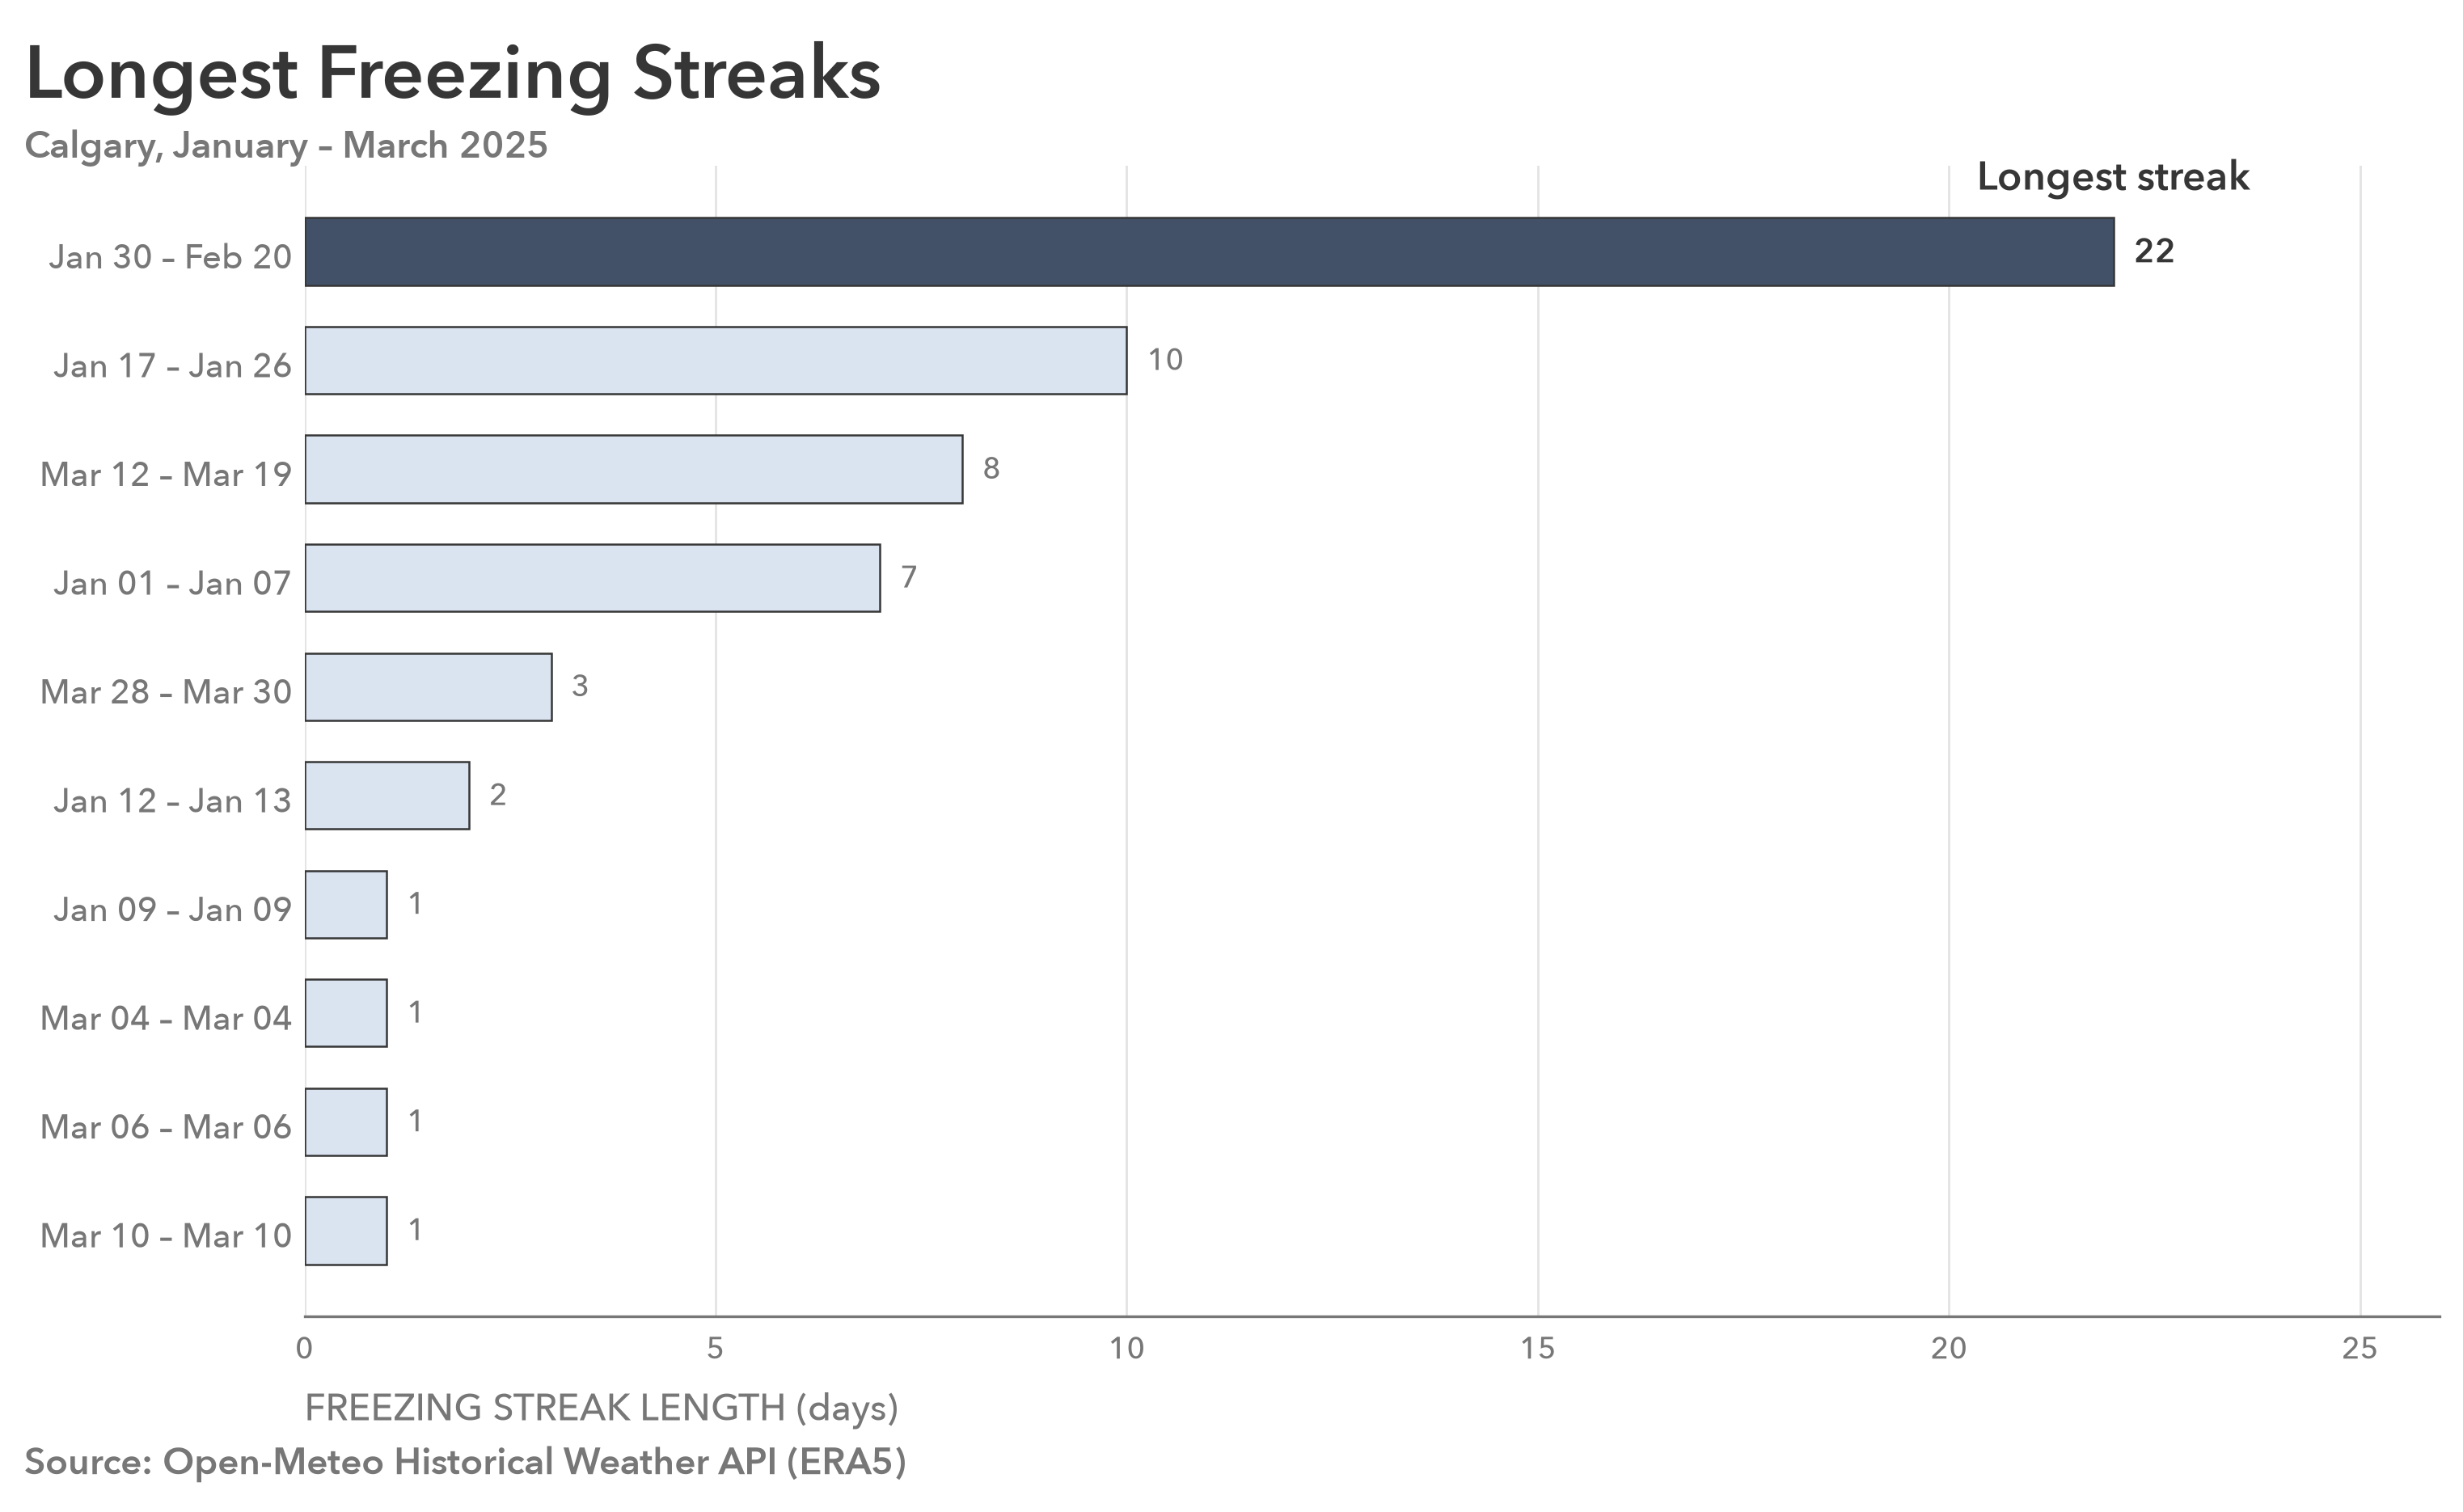

In [17]:
# Visualize

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 500

fig, ax = plt.subplots(figsize = (11, 6.5), dpi = 300)

fig.subplots_adjust(
    left = 0.13,
    right = 0.93,
    top = 0.83,
    bottom = 0.10
)

STRUCTURE = "#777777"
GRID = "#B3B3B3"
BLUE = "#425167"
LIGHT = "#DAE3F0"
TITLE = "#363636"

# Plot

colors = [BLUE if highlight else LIGHT for highlight in output_df["highlight"]]

bars = ax.barh(output_df["period"], output_df["days"], height = 0.62, color = colors, edgecolor = TITLE, linewidth = 0.6)

# Emphasis

for bar, days, highlight in zip(bars, output_df["days"], output_df["highlight"]):
    ax.annotate(f"{days}",
                (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext = (6, 0),
                textcoords = "offset points",
                ha = "left",
                va = "center",
                fontsize = 10 if highlight else 9,
                fontweight = 600 if highlight else 500,
                color = TITLE if highlight else STRUCTURE
    )

longest_bar = bars[output_df["highlight"].idxmax()]

ax.annotate("Longest streak",
            (longest_bar.get_width(), longest_bar.get_y() + longest_bar.get_height() / 2),
            xytext = (0, 14),
            textcoords = "offset points",
            ha = "center",
            va = "bottom",
            fontsize = 12,
            fontweight = 600,
            color = TITLE
)

# Scale & Axes

ax.set_xlim(0, output_df["days"].max() * 1.18)

ax.set_xlabel("FREEZING STREAK LENGTH (days)", loc = "left", fontsize = 11, fontweight = 500, color = STRUCTURE)

# Ticks

ax.tick_params(axis = "x", labelsize = 9, length = 0, labelcolor = STRUCTURE)
ax.tick_params(axis = "y", labelsize = 10, length = 0, labelcolor = STRUCTURE)

# Styling

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(STRUCTURE)

ax.set_axisbelow(True)
ax.grid(axis = "x", color = GRID, linewidth = 0.7, alpha = 0.35)

# Composition

fig.suptitle("Longest Freezing Streaks", x = 0.025, y = 0.92, ha = "left", va = "top", fontweight = 600, fontsize = 22, color = TITLE)

fig.text(0.025, 0.835, "Calgary, January – March 2025", fontsize = 11, fontweight = 600, color = STRUCTURE)

fig.text(0.025, 0, "Source: Open-Meteo Historical Weather API (ERA5)", fontsize = 11, color = STRUCTURE, fontweight = 600)

# Output

fig.savefig("outputs/longest-freezing-streaks-early-2025.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()